# SSD300 (VGG-16) — Training

Fine-tunes torchvision's COCO-pretrained model on Construction-PPE. The test-set evaluation is in
[`ssd300_eval.ipynb`](ssd300_eval.ipynb).

torchvision's SSD reference augmentation (photometric distort, zoom-out, IoU crop) is **not** used, so SSD gets the same
augmentation as the other three models.

| Setting | Value |
|---|---|
| Input size | 640×640 from the pipeline, resized to 300×300 inside the model |
| Optimizer | SGD, lr 0.002 × batch / 32, momentum 0.9, weight decay 4e-5 (torchvision reference) |
| LR schedule | cosine decay over `EPOCHS` |
| Batch size | 32 |
| Epochs | 10 (scratch run; training runs use up to `MAX_EPOCHS` = 200) |
| Early stopping | patience 15 on validation mAP@50-95 |
| Checkpoint | best validation mAP@50-95 → `models/ssd300/weights/best.pt` |

> **Scratch run.** `EPOCHS` is set to **10** in the hyperparameter cell so the notebook runs end to end quickly; use
> a higher value such as `MAX_EPOCHS` (200) for training runs.

**Data augmentation** uses the same family (steps, ranges and probabilities) in all four models
(`ppe_detection_evaluation.dataset.augmentations`). The torchvision models apply it with Albumentations.

| # | Augmentation | Parameters | p |
|---|---|---|---|
| A1 | Horizontal flip | — | 0.5 |
| A2 | Scale + translate | scale 0.75–1.25, translate ±10 %, gray fill 114 | 1.0 |
| A3 | Brightness jitter | brightness factor 0.6–1.4 | 1.0 |

Every image is first resized to 640×640. Boxes keeping less than 40 % of their area, or narrower than 3 px, are dropped.
Validation and test images are only resized.

In [ ]:
import json

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16
from torchvision.models.detection.ssd import SSDClassificationHead

from ppe_detection_evaluation import SSD300, EvaluationFramework
from ppe_detection_evaluation.classes import DEFAULT_CLASS_NAMES
from ppe_detection_evaluation.dataset.augmentations import build_train_transform
from ppe_detection_evaluation.dataset.core import (
    check_dataset,
    class_box_counts,
    download_dataset,
    list_images,
    load_eval_example,
    xyxy_to_cxcywh,
)
from ppe_detection_evaluation.dataset.torchvision_adapter import TorchvisionDataset, collate, seed_worker
from ppe_detection_evaluation.experiment import DATA_ROOT, IMAGE_SIZE, MAX_EPOCHS, MODELS_DIR, PRETRAINED_DIR, SEED
from ppe_detection_evaluation.utilities.visualize import plot_examples

## Hyperparameters

Everything tunable for this model is set in the next cell. `SEED`, `IMAGE_SIZE` and `MAX_EPOCHS` are shared by all four
notebooks (`experiment.py`): the seed makes runs reproducible. Epochs, early stopping, batch size and optimizer settings
are chosen per model.

In [2]:
EPOCHS = 10  # set higher for training runs, such as MAX_EPOCHS
PATIENCE = 15  # epochs without a validation mAP@50-95 improvement
BATCH_SIZE = 32                 # SSD's 300×300 input fits the reference recipe's batch of 32
LR = 0.002 * BATCH_SIZE / 32    # torchvision SSD reference: lr 0.002 at batch 32, scaled linearly
MOMENTUM = 0.9
WEIGHT_DECAY = 4e-5

In [3]:
# SEED, DATA_ROOT and the model folders come from experiment.py and are shared by all four notebooks.
RUN_DIR = MODELS_DIR / "ssd300"          # training curves and history
WEIGHTS_DIR = RUN_DIR / "weights"       # best.pt / last.pt
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(PRETRAINED_DIR / "torchvision")  # COCO weights download here instead of ~/.cache

NUM_CLASSES = len(DEFAULT_CLASS_NAMES) + 1  # + background at index 0

torch.manual_seed(SEED)  # makes the new head's random initialisation reproducible
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {DEVICE} | Classes: {NUM_CLASSES} (incl. background) | Epochs: {EPOCHS} | Batch: {BATCH_SIZE}")

Device: cuda | Classes: 6 (incl. background) | Epochs: 10 | Batch: 32


## 1. Dataset

[Ultralytics Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/): 7 of its 11 classes are
kept: `person` and the present/absent pairs helmet / no_helmet, vest / no_vest and gloves / no_gloves; boxes of the other classes are
dropped when the labels are written. `download_dataset` is a no-op once
`data/construction-ppe` exists, so all four notebooks share one copy.

In [ ]:
download_dataset(DATA_ROOT)
splits = check_dataset(DATA_ROOT)  # raises if the class order differs from DEFAULT_CLASS_NAMES

counts = {split: class_box_counts(DATA_ROOT, split) for split in splits}
print(f"{'Boxes':<10}" + "".join(f"{split.capitalize():>8}" for split in splits))
for name in counts["train"]:
    print(f"{name:<10}" + "".join(f"{counts[split][name]:>8}" for split in splits))
print("-" * (10 + 8 * len(splits)))
print(f"{'Images':<10}" + "".join(f"{n:>8}" for n in splits.values()))

## 2. Training data

`TorchvisionDataset` applies the shared augmentation to each image and returns it in
torchvision's format: a float image in [0, 1] and a target with pixel xyxy `boxes` and `labels` shifted by +1 (0 is
background). Normalisation and resizing to the network input are left to the model's own transform.

In [ ]:
train_ds = TorchvisionDataset(DATA_ROOT, "train", build_train_transform(seed=SEED))
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    collate_fn=collate,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
)
print(f"Train: {len(train_ds)} images | {len(train_loader)} batches per epoch")

In [ ]:
# Four training images (columns), each drawn three times (rows) to show the augmentation's range
examples, titles = [], []
for draw in range(3):
    for i in range(4):
        image, target = train_ds[i]
        image = (image * 255).round().byte().permute(1, 2, 0).numpy()
        examples.append((image, target["boxes"].numpy(), target["labels"].numpy() - 1))
        titles.append(f"draw {draw} · {train_ds.image_paths[i].name[:20]}")
plot_examples(examples, titles);

## 3. Model

COCO-pretrained SSD300 with its classification head replaced: one conv layer per feature map (six in total), now
predicting 8 classes (7 + background) per anchor. The VGG-16 backbone, the box-regression head and the anchors keep
their COCO weights. The shared pipeline outputs 640×640 images; SSD resizes them to 300×300 internally and maps its
boxes back to 640×640.

In [8]:
model = ssd300_vgg16(
    weights=SSD300_VGG16_Weights.COCO_V1,
    score_thresh=0.001,  # same detection threshold as the other models (torchvision default 0.01)
)

# The pretrained classification head outputs 91 COCO classes; replace it with one for our 7 classes + background.
# The box-regression head is class-agnostic, so it keeps its COCO weights.
in_channels = [layer.in_channels for layer in model.head.classification_head.module_list]
num_anchors = model.anchor_generator.num_anchors_per_location()
model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, NUM_CLASSES)
model = model.to(DEVICE)

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params:     {total:,}")
print(f"Trainable params: {trainable:,}")

Total params:     24,280,556
Trainable params: 24,241,836


## 4. Training

`train_one_epoch` runs one pass over the augmented training set; `validation_loss` computes the same loss on a split
without augmentation; `evaluate` scores a split with the evaluation framework. After each epoch the validation split is scored and the checkpoint with the best
validation mAP@50-95 is kept.

In [ ]:
def train_one_epoch(model, loader, optimizer, epoch):
    model.train()
    running_loss, total_images = 0.0, 0

    for step, (images, targets) in enumerate(loader):
        images = [img.to(DEVICE) for img in images]
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]
        loss = sum(model(images, targets).values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss is {loss.item()} at epoch {epoch}, step {step}")

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        total_images += len(images)

    return running_loss / total_images  # mean loss per image over the epoch

In [10]:
@torch.inference_mode()
def evaluate(model, split):
    """Score a split with the evaluation framework; images are only resized to 640×640, no augmentation."""
    model.eval()
    fw = EvaluationFramework(SSD300)
    for path in list_images(DATA_ROOT, split):
        image, gt_boxes, gt_labels = load_eval_example(path)
        out = model([torch.from_numpy(image).permute(2, 0, 1).float().div(255).to(DEVICE)])[0]
        fw.add(
            path.stem,
            out["boxes"].cpu().numpy(),
            out["scores"].cpu().numpy(),
            out["labels"].cpu().numpy(),
            xyxy_to_cxcywh(gt_boxes, IMAGE_SIZE, IMAGE_SIZE),
            gt_labels,
        )
    return fw.evaluate()

In [11]:
@torch.inference_mode()
def validation_loss(model, split):
    """Mean loss per image on a split, the same quantity `train_one_epoch` reports.

    Detection models only return losses in train mode. BatchNorm layers stay in eval mode, so that scoring the
    validation split does not update their running statistics.
    """
    model.train()
    for module in model.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
    paths = list_images(DATA_ROOT, split)
    total_loss = 0.0
    for start in range(0, len(paths), BATCH_SIZE):
        images, targets = [], []
        for path in paths[start : start + BATCH_SIZE]:
            image, boxes, labels = load_eval_example(path)
            images.append(torch.from_numpy(image).permute(2, 0, 1).float().div(255).to(DEVICE))
            targets.append({
                "boxes": torch.from_numpy(boxes).reshape(-1, 4).to(DEVICE),
                "labels": torch.from_numpy(labels + 1).to(DEVICE),  # +1: index 0 is background
            })
        total_loss += sum(model(images, targets).values()).item() * len(images)
    return total_loss / len(paths)

In [12]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_map = -1.0
epochs_since_best = 0
history = {"train_loss": [], "val_loss": [], "val_map50": [], "val_map": []}

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, epoch)
    scheduler.step()
    val_loss = validation_loss(model, "valid")
    val = evaluate(model, "valid")["detection"]["groups"]["all"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_map50"].append(val["mAP50"])
    history["val_map"].append(val["mAP"])
    print(f"Epoch {epoch + 1:3d}/{EPOCHS}  loss={train_loss:.4f}/{val_loss:.4f}  val mAP@50={val['mAP50']:.4f}  mAP@50-95={val['mAP']:.4f}")

    if val["mAP"] > best_map:
        best_map = val["mAP"]
        epochs_since_best = 0
        torch.save(model.state_dict(), WEIGHTS_DIR / "best.pt")
        print(f"  → Best saved (mAP@50-95={best_map:.4f})")
    else:
        epochs_since_best += 1
        if epochs_since_best >= PATIENCE:
            print(f"Early stopping: no mAP@50-95 improvement for {PATIENCE} epochs")
            break

torch.save(model.state_dict(), WEIGHTS_DIR / "last.pt")
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))

Epoch   1/10  loss=7.6838/4.7361  val mAP@50=0.3022  mAP@50-95=0.1286
  → Best saved (mAP@50-95=0.1286)
Epoch   2/10  loss=4.3121/3.9540  val mAP@50=0.4862  mAP@50-95=0.2190
  → Best saved (mAP@50-95=0.2190)
Epoch   3/10  loss=3.7794/3.7031  val mAP@50=0.5550  mAP@50-95=0.2533
  → Best saved (mAP@50-95=0.2533)
Epoch   4/10  loss=3.5460/3.5075  val mAP@50=0.5752  mAP@50-95=0.2672
  → Best saved (mAP@50-95=0.2672)
Epoch   5/10  loss=3.4124/3.4465  val mAP@50=0.5846  mAP@50-95=0.2715
  → Best saved (mAP@50-95=0.2715)
Epoch   6/10  loss=3.2887/3.3892  val mAP@50=0.6125  mAP@50-95=0.2811
  → Best saved (mAP@50-95=0.2811)
Epoch   7/10  loss=3.2234/3.3281  val mAP@50=0.6020  mAP@50-95=0.2830
  → Best saved (mAP@50-95=0.2830)
Epoch   8/10  loss=3.1739/3.2851  val mAP@50=0.6149  mAP@50-95=0.2967
  → Best saved (mAP@50-95=0.2967)
Epoch   9/10  loss=3.1015/3.2740  val mAP@50=0.6113  mAP@50-95=0.2963
Epoch  10/10  loss=3.0780/3.2756  val mAP@50=0.6190  mAP@50-95=0.2981
  → Best saved (mAP@50-95=0.

1035

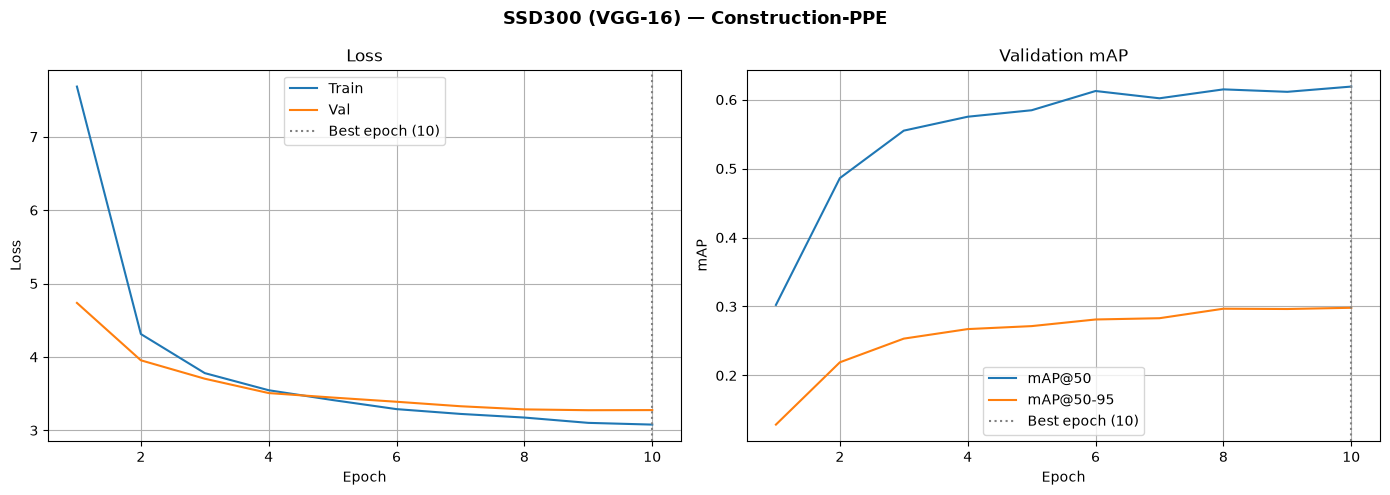

In [13]:
epochs_x = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmax(history["val_map"])) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(epochs_x, history["train_loss"], label="Train")
ax1.plot(epochs_x, history["val_loss"], label="Val")
ax1.set(xlabel="Epoch", ylabel="Loss", title="Loss")
ax2.plot(epochs_x, history["val_map50"], label="mAP@50")
ax2.plot(epochs_x, history["val_map"], label="mAP@50-95")
ax2.set(xlabel="Epoch", ylabel="mAP", title="Validation mAP")
for ax in (ax1, ax2):
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5, label=f"Best epoch ({best_epoch})")
    ax.legend()
    ax.grid(True)

plt.suptitle("SSD300 (VGG-16) — Construction-PPE", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()

Next: evaluate `models/ssd300/weights/best.pt` on the test split with [`ssd300_eval.ipynb`](ssd300_eval.ipynb).